# 3.0 - Regression Modeling for Delay Prediction
**Week 3** | `src/modeling/train.py`

**Target:** `hours_delayed = actual delivery hours - SLA hours` (continuous, negative = early). Total delivery hours are derived as `SLA + predicted delay`.

**Leakage controls**
* Only dispatch-time information is used as features.
* Vendor performance uses `merge_asof` on *already-delivered* shipments.
* **Chronological split** (train = past, test = last 20 % of time) and `TimeSeriesSplit` for tuning - never a random shuffle.

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, features as F
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
def save(name):
    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(config.FIGURES_DIR / name, dpi=140, bbox_inches="tight")
import joblib
from sklearn.inspection import permutation_importance
from src.modeling import train as T
table = pd.read_csv(config.DATA_PROCESSED / 'shipments_enriched.csv', parse_dates=['dispatch_time','delivery_time'])
train, test, cut = T.chronological_split(table)
print('train:', len(train), '| test:', len(test), '| cut-off:', cut)
print('train period:', train.dispatch_time.min().date(), '->', train.dispatch_time.max().date(), '| test:', test.dispatch_time.min().date(), '->', test.dispatch_time.max().date())

train: 24000 | test: 6000 | cut-off: 2025-08-24 07:28:48
train period: 2024-01-01 -> 2025-08-24 | test: 2025-08-24 -> 2025-12-31


## 1. Baselines
If a model cannot beat these, it adds nothing.

In [2]:
base = T.baselines(train, test); base.round(3)

,delay_rmse,delay_mae,delay_r2,delivery_rmse,delivery_mae,delivery_r2
predict train-mean delay,2.710,1.820,-0.039,2.710,1.820,0.991
trust the SLA (delay = 0),2.929,2.188,-0.214,2.929,2.188,0.990


## 2. Ridge Regression vs Random Forest (One-Hot Encoded categoricals)
Hyper-parameters tuned with `GridSearchCV` + `TimeSeriesSplit` on the training period only.

In [3]:
results, fitted, train, test, cut = T.run_experiment(table)
results.drop(columns='best_params').round(3)

,model,cv_rmse,delay_rmse,delay_mae,delay_r2,delivery_rmse,delivery_mae,delivery_r2
0,random_forest,1.713,1.523,1.019,0.672,1.523,1.019,0.997
1,ridge,2.321,2.230,1.544,0.296,2.230,1.544,0.994


In [4]:
print(results[['model','best_params']].to_string(index=False))
best_name = results.iloc[0].model; best = fitted[best_name]
m = T.evaluate(best, test); T.save_model(best, 'delay_model', m)
results.to_csv(config.DATA_PROCESSED / 'model_comparison.csv', index=False); base.to_csv(config.DATA_PROCESSED / 'baseline_comparison.csv')
print('\nSelected:', best_name)
print({k: round(v, 3) for k, v in m.items()})
print('\nR2 >= 0.65 (delay):', 'PASS' if m['delay_r2'] >= .65 else 'FAIL', '| R2 (total delivery hours):', round(m['delivery_r2'], 3))
print(f"RMSE reduction vs 'trust the SLA': {1 - m['delay_rmse']/base.loc['trust the SLA (delay = 0)','delay_rmse']:.0%}")

        model                    best_params
random_forest {'model__min_samples_leaf': 3}
        ridge        {'model__alpha': 100.0}



Selected: random_forest
{'delay_rmse': 1.523, 'delay_mae': 1.019, 'delay_r2': 0.672, 'delivery_rmse': 1.523, 'delivery_mae': 1.019, 'delivery_r2': 0.997}

R2 >= 0.65 (delay): PASS | R2 (total delivery hours): 0.997
RMSE reduction vs 'trust the SLA': 48%


> **Reading the two R-squared values.** `delivery_r2` is ~0.99 even for the naive 'trust the SLA' baseline, because total delivery time is dominated by distance. It is therefore a weak test. The stricter and more meaningful number is the R-squared on **hours delayed** (and RMSE vs the baselines), which we treat as the headline.

## 3. Actual vs predicted

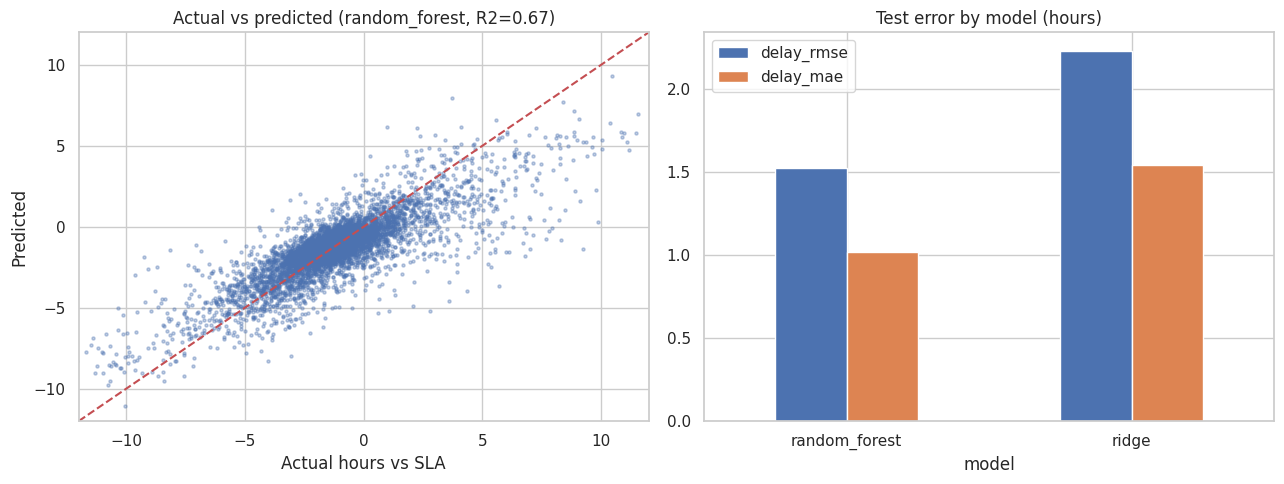

In [5]:
pred = best.predict(test[T.FEATURES]); test['pred'] = pred; test['resid'] = test.hours_delayed - pred
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(test.hours_delayed, pred, s=5, alpha=.35); lim = [-12, 12]; ax[0].plot(lim, lim, 'r--'); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel('Actual hours vs SLA'); ax[0].set_ylabel('Predicted'); ax[0].set_title('Actual vs predicted (%s, R2=%.2f)' % (best_name, m['delay_r2']))
cmp = results.set_index('model')[['delay_rmse','delay_mae']]; cmp.plot.bar(ax=ax[1], title='Test error by model (hours)'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); save('08_actual_vs_predicted.png'); plt.show()

## 4. Residual analysis - is the model systematically biased?

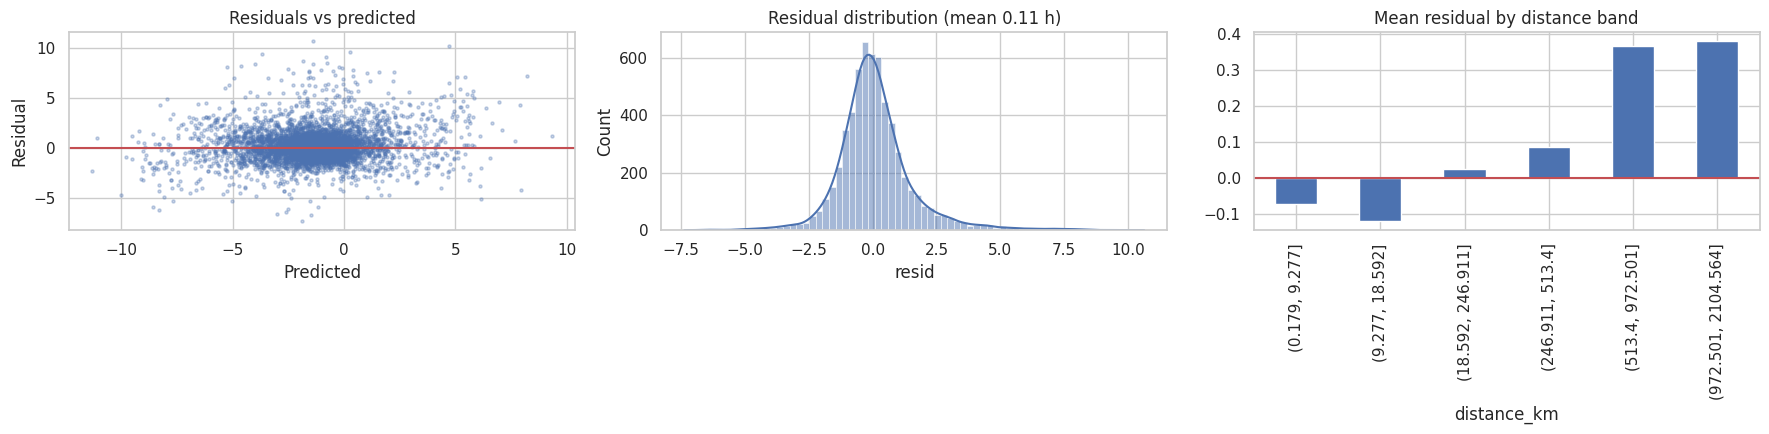

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].scatter(pred, test.resid, s=5, alpha=.3); ax[0].axhline(0, c='r'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Residual'); ax[0].set_title('Residuals vs predicted')
sns.histplot(test.resid, bins=70, kde=True, ax=ax[1]); ax[1].set_title('Residual distribution (mean %.2f h)' % test.resid.mean())
bins = pd.qcut(test.distance_km, 6, duplicates='drop'); test.groupby(bins).resid.mean().plot.bar(ax=ax[2], title='Mean residual by distance band'); ax[2].axhline(0, c='r')
plt.tight_layout(); save('09_residuals.png'); plt.show()

In [7]:
test['dow'] = test.dispatch_time.dt.day_name()
print('Mean residual by day of week (h):'); print(test.groupby('dow').resid.mean().round(3).to_dict())
print('\nLargest |mean residual| by carrier / by origin city (h):', round(test.groupby('carrier_id').resid.mean().abs().max(), 3), '/', round(test.groupby('origin_city').resid.mean().abs().max(), 3))

Mean residual by day of week (h):
{'Friday': 0.312, 'Monday': 0.258, 'Saturday': 0.562, 'Sunday': -0.313, 'Thursday': -0.046, 'Tuesday': 0.033, 'Wednesday': -0.156}

Largest |mean residual| by carrier / by origin city (h): 0.893 / 0.187


Check the residual plots and the numbers above: if residuals are centred near zero with no trend against prediction, distance, weekday, carrier or city, the model is **not systematically biased**. The heavier right tail comes from random breakdowns, which no dispatch-time feature can predict.

## 5. What drives delay? (permutation importance)

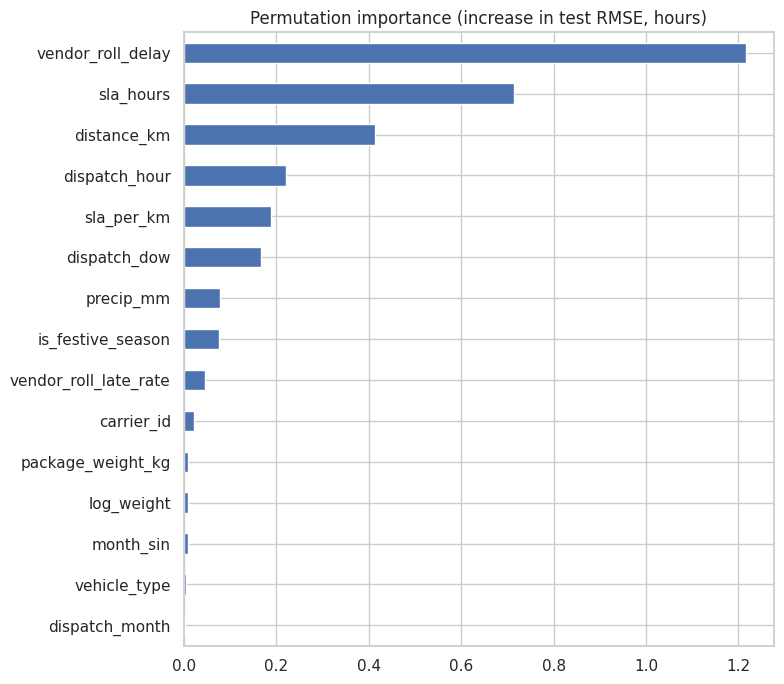

vendor_roll_delay    1.216
sla_hours            0.715
distance_km          0.414
dispatch_hour        0.222
sla_per_km           0.189
dispatch_dow         0.168
precip_mm            0.077
is_festive_season    0.076
dtype: float64

In [8]:
pi = permutation_importance(best, test[T.FEATURES], test.hours_delayed, scoring='neg_root_mean_squared_error', n_repeats=5, random_state=config.RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=T.FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 7)); imp.tail(15).plot.barh(ax=ax, color='C0'); ax.set_title('Permutation importance (increase in test RMSE, hours)')
plt.tight_layout(); save('10_feature_importance.png'); plt.show()
imp.sort_values(ascending=False).head(8).round(3)

## 6. Using the regression as a late-shipment alert
Treat `predicted delay > 0` as 'will breach SLA' and compare with reality.

precision 0.778 | recall 0.581


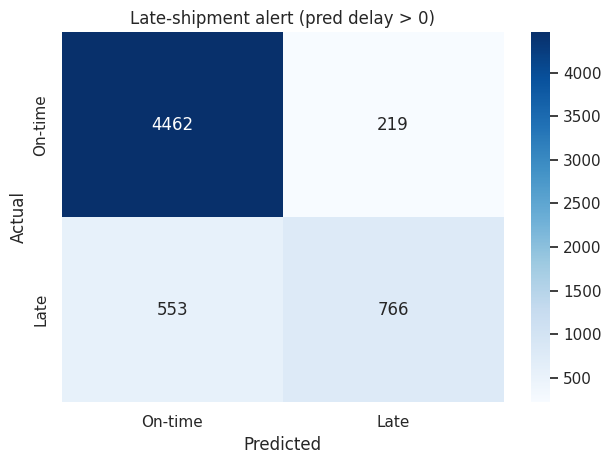

In [9]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix
yp = (pred > 0).astype(int); yt = test.is_late.to_numpy()
print('precision', round(precision_score(yt, yp), 3), '| recall', round(recall_score(yt, yp), 3))
sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt='d', cmap='Blues', xticklabels=['On-time','Late'], yticklabels=['On-time','Late']); plt.title('Late-shipment alert (pred delay > 0)'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); save('11_late_alert_confusion.png'); plt.show()

## Takeaways
* Random Forest beats Ridge: delay depends on **interactions** (rain x distance, carrier x season) that a linear model cannot represent.
* The model beats both baselines on RMSE and clears the **R-squared >= 0.65** requirement on the stricter delay target.
* Remaining error is mostly unpredictable breakdowns.
* Metrics are from **synthetic** data: re-validate on real client data.

**Next:** operational dashboard data (4.0).